In [48]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

In [49]:
df = pd.read_csv("data_CASE_group_18.csv")
print(df.shape)

(2467, 39)


In [50]:
cols = df.columns[4:39]
df[cols] = df[cols].astype(float).replace(9, np.nan)
df['all_missing'] = df[cols].isna().all(axis=1)
df_clean = df.loc[~df['all_missing']].drop(columns='all_missing')
print(df_clean.shape)

(2383, 39)


In [51]:
#duplicate
df_clean = df_clean.drop_duplicates()
print(df_clean.shape)

#outlier alone
df_clean = df_clean[df_clean['Price'] < 165000000]
print(df_clean.shape)

(1844, 39)
(1843, 39)


12500000.0
EXPENSIVE
0    1486
1     357
Name: count, dtype: int64


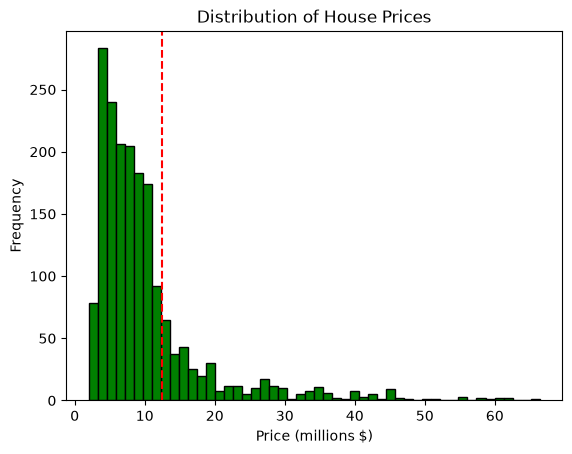

In [52]:
#BLOCK1: 80% less expensive and 20% more expensive
q80 = df_clean['Price'].quantile(0.80)
df_clean['EXPENSIVE'] = (df_clean['Price'] > q80).astype(int)
print(q80)
print(df_clean['EXPENSIVE'].value_counts())

plt.hist(df_clean['Price'] / 1000000, bins=50, edgecolor="black", color="green")
plt.axvline(q80 / 1000000, color="red", linestyle="--")
plt.xlabel("Price (millions $)")
plt.ylabel("Frequency")
plt.title("Distribution of House Prices")
plt.show()

In [53]:
#BLOCK2:SPLIT 60/20/20

y = df_clean['EXPENSIVE']
X = df_clean.drop(columns=['Price', 'EXPENSIVE']).astype(float)
print(X.shape)

#Training, Validation, Testing Data
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)
print(len(X_train), len(X_val), len(X_test))
print(y_train.mean(), y_val.mean(), y_test.mean())

#standardization (useful for logit and neural network) 
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)


(1843, 38)
1105 369 369
0.19004524886877827 0.1951219512195122 0.2032520325203252


In [54]:
#BLOCK3: Logit model4
from sklearn.linear_model import LogisticRegression
logit = LogisticRegression(C=np.inf)
logit.fit(X_train_s, y_train)
print(logit.score(X_val_s, y_val))

0.948509485094851


In [55]:
#BLOCK4: Gaussian Naive Bayes model5
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
gnb.fit(X_train_s, y_train)
print(gnb.score(X_val_s, y_val))

0.7560975609756098


13
12


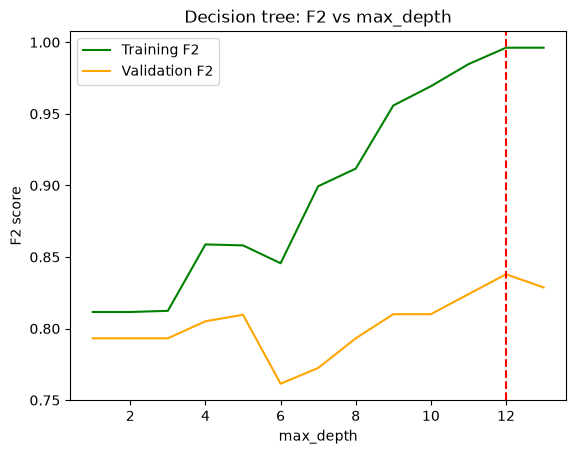

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

In [56]:
#BLOCK5: Decision tree model6
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import fbeta_score

#Checking how deep the tree goes without limit
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train_s, y_train)
print(full_tree.get_depth())

#Looping over the depths
depths = range(1, full_tree.get_depth() + 1)
tree_train_f2, tree_val_f2 = [], []

for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_train_s, y_train)
    tree_train_f2.append(fbeta_score(y_train, m.predict(X_train_s), beta=2))
    tree_val_f2.append(fbeta_score(y_val, m.predict(X_val_s), beta=2))

best_depth = depths[np.argmax(tree_val_f2)]
print(best_depth)

plt.plot(depths, tree_train_f2, color="green", label="Training F2")
plt.plot(depths, tree_val_f2, color="orange", label="Validation F2")
plt.axvline(best_depth, color="red", linestyle="--")
plt.xlabel("max_depth")
plt.ylabel("F2 score")
plt.title("Decision tree: F2 vs max_depth")
plt.legend()
plt.show()

#Final tree
tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
tree.fit(X_train_s, y_train)

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
[0.8146067415730337, 0.7977207977207977, 0.7977207977207977, 0.8096590909090909, 0.8356940509915014, 0.8215297450424929]
64-32


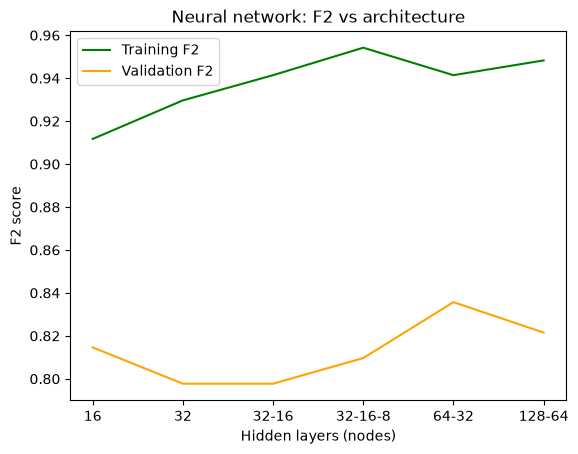

In [57]:
#BLOCK6: Neural network model7
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train, 2)

architectures = [(16,), (32,), (32, 16), (32, 16, 8), (64, 32), (128, 64)]
nn_models, nn_train_f2, nn_val_f2 = [], [], []

for arch in architectures:
    tf.keras.utils.set_random_seed(42)
    model = Sequential()
    model.add(Input(shape=(38,)))
    for nodes in arch:
        model.add(Dense(nodes, activation='relu'))
        model.add(Dropout(0.2))
    model.add(Dense(2, activation='softmax'))
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    model.fit(X_train_s, y_train_cat, epochs=50, batch_size=10, verbose=0)

    pred_train = np.argmax(model.predict(X_train_s), axis=1)
    pred_val = np.argmax(model.predict(X_val_s), axis=1)
    nn_models.append(model)
    nn_train_f2.append(fbeta_score(y_train, pred_train, beta=2))
    nn_val_f2.append(fbeta_score(y_val, pred_val, beta=2))

print(nn_val_f2)

names = ['16', '32', '32-16', '32-16-8', '64-32', '128-64']
best_nn = np.argmax(nn_val_f2)
print(names[best_nn])

plt.plot(names, nn_train_f2, color="green", label="Training F2")
plt.plot(names, nn_val_f2, color="orange", label="Validation F2")
plt.xlabel("Hidden layers (nodes)")
plt.ylabel("F2 score")
plt.title("Neural network: F2 vs architecture")
plt.legend()
plt.show()

nn = nn_models[best_nn]

In [58]:
#BLOCK7: Table 6 on the test set
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

pred_logit = logit.predict(X_test_s)
pred_gnb = gnb.predict(X_test_s)
pred_tree = tree.predict(X_test_s)
pred_nn = np.argmax(nn.predict(X_test_s), axis=1)

results = []
for name, pred in [('Logit', pred_logit), ('Naive Bayes', pred_gnb), ('Decision tree', pred_tree), ('Neural network', pred_nn)]:
    results.append([name,
                    accuracy_score(y_test, pred),
                    recall_score(y_test, pred),
                    precision_score(y_test, pred),
                    f1_score(y_test, pred),
                    fbeta_score(y_test, pred, beta=2)])

table6 = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Recall', 'Precision', 'F1', 'F2'])
print(table6.round(3))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
            Model  Accuracy  Recall  Precision     F1     F2
0           Logit     0.930   0.733      0.902  0.809  0.762
1     Naive Bayes     0.780   0.680      0.472  0.557  0.625
2   Decision tree     0.916   0.787      0.797  0.792  0.789
3  Neural network     0.940   0.787      0.908  0.843  0.808


1105 185 553
12


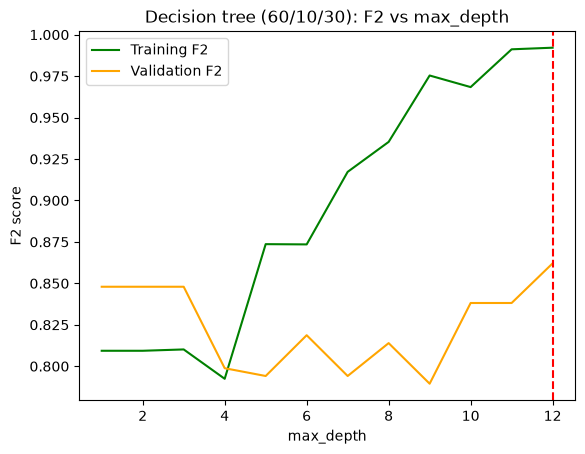

           Model  Accuracy  Recall  Precision     F1     F2
0          Logit     0.924   0.737      0.888  0.806  0.763
1    Naive Bayes     0.770   0.627      0.471  0.538  0.588
2  Decision tree     0.911   0.703      0.856  0.772  0.729


In [59]:
#BLOCK8: Robustness 60/10/30 
X_temp, X_test_r1, y_temp, y_test_r1 = train_test_split(X, y, test_size=0.30, random_state=42)
X_train_r1, X_val_r1, y_train_r1, y_val_r1 = train_test_split(X_temp, y_temp, test_size=1/7, random_state=42)
print(len(X_train_r1), len(X_val_r1), len(X_test_r1))

scaler_r1 = StandardScaler()
X_train_r1_s = scaler_r1.fit_transform(X_train_r1)
X_val_r1_s = scaler_r1.transform(X_val_r1)
X_test_r1_s = scaler_r1.transform(X_test_r1)

logit_r1 = LogisticRegression(C=np.inf)
logit_r1.fit(X_train_r1_s, y_train_r1)

gnb_r1 = GaussianNB()
gnb_r1.fit(X_train_r1_s, y_train_r1)

full_tree_r1 = DecisionTreeClassifier(random_state=42)
full_tree_r1.fit(X_train_r1_s, y_train_r1)
depths_r1 = range(1, full_tree_r1.get_depth() + 1)
tree_train_f2_r1, tree_val_f2_r1 = [], []

for d in depths_r1:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_train_r1_s, y_train_r1)
    tree_train_f2_r1.append(fbeta_score(y_train_r1, m.predict(X_train_r1_s), beta=2))
    tree_val_f2_r1.append(fbeta_score(y_val_r1, m.predict(X_val_r1_s), beta=2))

best_depth_r1 = depths_r1[np.argmax(tree_val_f2_r1)]
print(best_depth_r1)

plt.plot(depths_r1, tree_train_f2_r1, color="green", label="Training F2")
plt.plot(depths_r1, tree_val_f2_r1, color="orange", label="Validation F2")
plt.axvline(best_depth_r1, color="red", linestyle="--")
plt.xlabel("max_depth")
plt.ylabel("F2 score")
plt.title("Decision tree (60/10/30): F2 vs max_depth")
plt.legend()
plt.show()

tree_r1 = DecisionTreeClassifier(max_depth=best_depth_r1, random_state=42)
tree_r1.fit(X_train_r1_s, y_train_r1)

results_r1 = []
for name, model_r1 in [('Logit', logit_r1), ('Naive Bayes', gnb_r1), ('Decision tree', tree_r1)]:
    pred = model_r1.predict(X_test_r1_s)
    results_r1.append([name,
                       accuracy_score(y_test_r1, pred),
                       recall_score(y_test_r1, pred),
                       precision_score(y_test_r1, pred),
                       f1_score(y_test_r1, pred),
                       fbeta_score(y_test_r1, pred, beta=2)])

table7 = pd.DataFrame(results_r1, columns=['Model', 'Accuracy', 'Recall', 'Precision', 'F1', 'F2'])
print(table7.round(3))

921 461 461
1


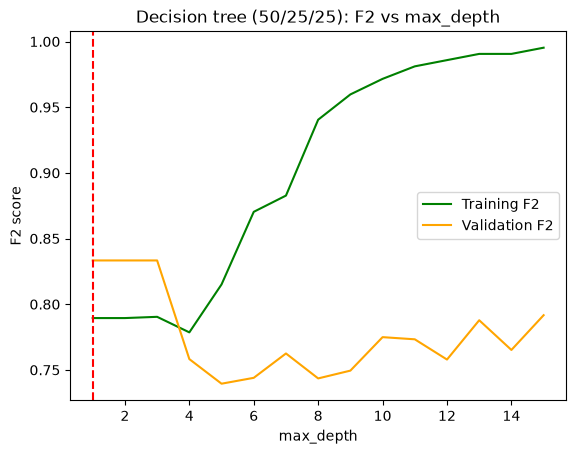

           Model  Accuracy  Recall  Precision     F1     F2
0          Logit     0.939   0.750      0.932  0.831  0.781
1    Naive Bayes     0.794   0.663      0.488  0.562  0.619
2  Decision tree     0.913   0.728      0.817  0.770  0.744


In [60]:
#BLOCK9: Robustness 50/25/25
X_temp, X_test_r2, y_temp, y_test_r2 = train_test_split(X, y, test_size=0.25, random_state=42)
X_train_r2, X_val_r2, y_train_r2, y_val_r2 = train_test_split(X_temp, y_temp, test_size=1/3, random_state=42)
print(len(X_train_r2), len(X_val_r2), len(X_test_r2))

scaler_r2 = StandardScaler()
X_train_r2_s = scaler_r2.fit_transform(X_train_r2)
X_val_r2_s = scaler_r2.transform(X_val_r2)
X_test_r2_s = scaler_r2.transform(X_test_r2)

logit_r2 = LogisticRegression(C=np.inf)
logit_r2.fit(X_train_r2_s, y_train_r2)

gnb_r2 = GaussianNB()
gnb_r2.fit(X_train_r2_s, y_train_r2)

full_tree_r2 = DecisionTreeClassifier(random_state=42)
full_tree_r2.fit(X_train_r2_s, y_train_r2)
depths_r2 = range(1, full_tree_r2.get_depth() + 1)
tree_train_f2_r2, tree_val_f2_r2 = [], []

for d in depths_r2:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_train_r2_s, y_train_r2)
    tree_train_f2_r2.append(fbeta_score(y_train_r2, m.predict(X_train_r2_s), beta=2))
    tree_val_f2_r2.append(fbeta_score(y_val_r2, m.predict(X_val_r2_s), beta=2))

best_depth_r2 = depths_r2[np.argmax(tree_val_f2_r2)]
print(best_depth_r2)

plt.plot(depths_r2, tree_train_f2_r2, color="green", label="Training F2")
plt.plot(depths_r2, tree_val_f2_r2, color="orange", label="Validation F2")
plt.axvline(best_depth_r2, color="red", linestyle="--")
plt.xlabel("max_depth")
plt.ylabel("F2 score")
plt.title("Decision tree (50/25/25): F2 vs max_depth")
plt.legend()
plt.show()

tree_r2 = DecisionTreeClassifier(max_depth=best_depth_r2, random_state=42)
tree_r2.fit(X_train_r2_s, y_train_r2)

results_r2 = []
for name, model_r2 in [('Logit', logit_r2), ('Naive Bayes', gnb_r2), ('Decision tree', tree_r2)]:
    pred = model_r2.predict(X_test_r2_s)
    results_r2.append([name,
                       accuracy_score(y_test_r2, pred),
                       recall_score(y_test_r2, pred),
                       precision_score(y_test_r2, pred),
                       f1_score(y_test_r2, pred),
                       fbeta_score(y_test_r2, pred, beta=2)])

table8 = pd.DataFrame(results_r2, columns=['Model', 'Accuracy', 'Recall', 'Precision', 'F1', 'F2'])
print(table8.round(3))

In [61]:
#BLOCK10: Logit Area and Bedrooms vs Our best model
two_features = ['Area', 'No. of Bedrooms']
print(X[two_features].corr())

scaler2 = StandardScaler()
X_train2_s = scaler2.fit_transform(X_train[two_features])
X_test2_s = scaler2.transform(X_test[two_features])

logit2 = LogisticRegression(C=np.inf)
logit2.fit(X_train2_s, y_train)
pred_logit2 = logit2.predict(X_test2_s)

results10 = []
for name, pred in [('Logit (Area + Bedrooms)', pred_logit2), ('Neural network (all features)', pred_nn)]:
    results10.append([name,
                      accuracy_score(y_test, pred),
                      recall_score(y_test, pred),
                      precision_score(y_test, pred),
                      f1_score(y_test, pred),
                      fbeta_score(y_test, pred, beta=2)])

table9 = pd.DataFrame(results10, columns=['Model', 'Accuracy', 'Recall', 'Precision', 'F1', 'F2'])
print(table9.round(3))

                     Area  No. of Bedrooms
Area             1.000000         0.780915
No. of Bedrooms  0.780915         1.000000
                           Model  Accuracy  Recall  Precision     F1     F2
0        Logit (Area + Bedrooms)     0.908   0.640      0.873  0.738  0.676
1  Neural network (all features)     0.940   0.787      0.908  0.843  0.808
